# SDLC/NRZI reference notebook
Use this notebook to build one legacy SDLC transmit frame from address/control/payload bytes, compute FCS, bit-stuff, NRZI-encode, and generate a 32x oversampled waveform for comparison with hardware captures.

In [ ]:
import numpy as np
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt

OUT = Path('output')
OUT.mkdir(exist_ok=True)

## 1. Build Transmit Frame
Fill `addr`, `ctrl`, and `payload` using the final transmitted values from NEWDEC. For RFDEC, `ctrl=0x57`; for IFDEC (`modnum==23`), `ctrl=0x97`. NEWDEC uses `modnum` as the address byte and `tx_data_buf[0..bytcnt-1]` as the payload.

In [ ]:
addr = 0x79 # RF DEC: 0x01 - 0x16) 1 - 22 | IF DEC: (0x17) 23
ctrl = 0x98 # RF DEC: 0x57 | IF DEC: 0x97
payload = [ 0x07 ]
# Payload Length Byte Count RF DEC: 0x0d (13bytes) (104b) | IF DEC / IF DEC + HIGH DEC: 0x15 (21 bytes) (168b)

assert 0 <= addr <= 0xFF and 0 <= ctrl <= 0xFF
assert all(0 <= b <= 0xFF for b in payload)
frame_no_flags = [addr, ctrl] + payload

print(f"Frame (NO FLAG) (bin): {[format(b, '08b') for b in frame_no_flags]}")


Frame (NO FLAG) (bin): ['01111001', '10011000', '00000111']


## 2. Compute SDLC FCS (CRC-16/IBM-SDLC)
This cell computes the 16-bit frame check sequence over address, control, and information fields, then appends it little-endian as transmitted on the line.

In [ ]:
def crc16_ibm_sdlc(bits):

    crc = 0xFFFF
    poly = 0x1021 # x^16 + x^12 + x^5 + 1  [ 1 (0001 0000 0010 0001) ] -> [1 (0x1021)]

    for b in bits:
        msb = (crc >> 15) & 1
        crc = ((crc << 1) & 0xFFFF) | (b & 1)

        if msb:
            crc ^= poly


    crc ^= 0xFFFF
    return crc & 0xFFFF


fcs = crc16_ibm_sdlc(frame_no_flags)
fcs_lo = fcs & 0xFF
fcs_hi = (fcs >> 8) & 0xFF
frame_bytes = [0x7E] + frame_no_flags + [fcs_hi, fcs_lo] + [0x7E]
pd.DataFrame({
    'index': range(len(frame_bytes)),
    'byte_hex': [f'0x{b:02X}' for b in frame_bytes]
})

print(f"(FCS)) (bin): {[format(b, '08b') for b in [fcs_hi,fcs_lo] ]}")
print(f"(Frame Bytes)) (hex): {[f'0x{b:02X}' for b in frame_bytes]}")
print(f"(Frame Bytes)) (bin): {[format(b, '08b') for b in frame_bytes]}")


(FCS)) (bin): ['01110000', '11100101']
(Frame Bytes)) (hex): ['0x7E', '0x79', '0x98', '0x07', '0x70', '0xE5', '0x7E']
(Frame Bytes)) (bin): ['01111110', '01111001', '10011000', '00000111', '01110000', '11100101', '01111110']


## 3. Serialize bytes LSB-first
SDLC/HDLC controllers conventionally shift each byte least-significant bit first on the serial line, while flags remain the 0x7E bit pattern. This cell converts bytes to a serial bit list.

In [ ]:
def bytes_to_bits_lsb_first(byte_list):
    bits = []
    for b in byte_list:
        bits.extend([(b >> i) & 1 for i in range(8)])
    return bits

flag_bits = [(0x7E >> i) & 1 for i in range(8)]
body_bits = bytes_to_bits_lsb_first(frame_no_flags + [fcs_lo, fcs_hi])

len(body_bits), flag_bits

(40, [0, 1, 1, 1, 1, 1, 1, 0])

## 4. Bit-stuff between flags
Bit stuffing is applied only between flags. After five consecutive 1 bits in the frame body, insert a 0.

In [ ]:
def bitstuff(bits):
    stuffed = []
    ones = 0
    for bit in bits:
        stuffed.append(bit)
        if bit == 1:
            ones += 1
            if ones == 5:
                stuffed.append(0)
                ones = 0
        else:
            ones = 0
    return stuffed

stuffed_body_bits = bitstuff(body_bits)
full_bits = flag_bits + stuffed_body_bits + flag_bits
print('Unstuffed body bits:', len(body_bits))
print('Stuffed body bits  :', len(stuffed_body_bits))
print('Full frame bits    :', len(full_bits))

Unstuffed body bits: 40
Stuffed body bits  : 40
Full frame bits    : 56


In [ ]:
def bits_to_bytes(bits):
    assert len(bits) % 8 == 0
    out = []
    for i in range(0, len(bits), 8):
        byte = 0
        for b in bits[i:i+8]:
            byte = (byte << 1) | (b & 1)
        out.append(byte)
    return out
frame_bytes = bits_to_bytes(full_bits)
print("(Frame bytes) (hex):", [f"{b:02X}" for b in frame_bytes])
print("(Frame bytes) (bin):", [f"{b:08b}" for b in frame_bytes])

(Frame bytes) (hex): ['7E', '9E', '19', 'E0', 'A7', '0E', '7E']
(Frame bytes) (bin): ['01111110', '10011110', '00011001', '11100000', '10100111', '00001110', '01111110']


## 5. NRZI encode
For SDLC NRZI, data 0 causes a transition and data 1 causes no transition. The initial line level is arbitrary for comparison as long as decode uses the same convention.

In [ ]:
def nrzi_encode(bits, initial_level=1):
    level = initial_level
    out = []
    for bit in bits:
        if bit == 0:
            level ^= 1
        out.append(level)
    return out

nrzi_bits = nrzi_encode(full_bits, initial_level=1)
pd.DataFrame({
    'bit_index': range(min(64, len(full_bits))),
    'sdlc_bit': full_bits[:64],
    'nrzi_level': nrzi_bits[:64],
})


,bit_index,sdlc_bit,nrzi_level
0,0,0,0
1,1,1,0
2,2,1,0
3,3,1,0
4,4,1,0
5,5,1,0
6,6,1,0
7,7,0,1
8,8,1,1
9,9,0,0


## 6. Generate 32x oversampled waveform
The legacy link uses a 32x clock with DPLL-derived bit timing. This cell expands each bit into 32 samples so you can compare against a capture indexed by the 32x clock.

In [ ]:
bit_rate = 9600
oversample = 32
sample_rate = bit_rate * oversample

samples = np.repeat(nrzi_bits, oversample)
t = np.arange(len(samples)) / sample_rate
wave_df = pd.DataFrame({
    'sample_idx': np.arange(len(samples)),
    'time_s': t,
    'txd_level': samples.astype(int),
})
wave_df.head(20)

,sample_idx,time_s,txd_level
0,0,0.000000,0
1,1,0.000003,0
2,2,0.000007,0
3,3,0.000010,0
4,4,0.000013,0
5,5,0.000016,0
6,6,0.000020,0
7,7,0.000023,0
8,8,0.000026,0
9,9,0.000029,0


## 7. Save NZRI Waveform sampled with 32xCLK (DPLL)


In [ ]:
frame_df = pd.DataFrame({
    'index': range(len(frame_bytes)),
    'byte_hex': [f'0x{b:02X}' for b in frame_bytes],
    'byte_dec': frame_bytes,
})
bits_df = pd.DataFrame({
    'bit_index': range(len(full_bits)),
    'sdlc_bit': full_bits,
    'nrzi_level': nrzi_bits,
})
frame_df.to_csv(OUT / 'frame_bytes.csv', index=False)
bits_df.to_csv(OUT / 'frame_bits_nrzi.csv', index=False)
wave_df.to_csv(OUT / 'frame_waveform_32x.csv', index=False)
print(OUT / 'frame_bytes.csv')
print(OUT / 'frame_bits_nrzi.csv')
print(OUT / 'frame_waveform_32x.csv')

output/frame_bytes.csv
output/frame_bits_nrzi.csv
output/frame_waveform_32x.csv


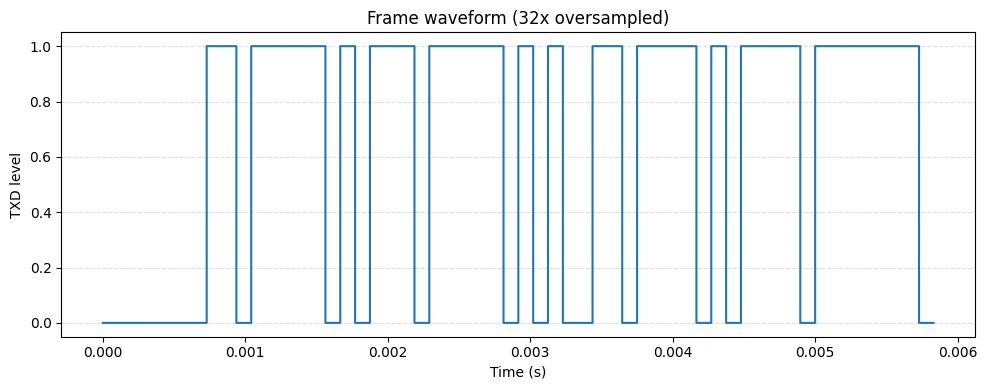

In [ ]:

df = pd.read_csv(OUT / 'frame_waveform_32x.csv')

plt.figure(figsize=(10, 4))
plt.step(df['time_s'], df['txd_level'], where='post')  # staircase, NRZI-style
plt.xlabel('Time (s)')
plt.ylabel('TXD level')
plt.title('Frame waveform (32x oversampled)')
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()